# Investigation of MUSIN-G Dataset


In [1]:
from pathlib import Path

import mne
import scipy
import sklearn
import torch
import torcheeg

import numpy as np
import pandas as pd
import soundfile as sf

from mne_bids import BIDSPath, find_matching_paths, get_entity_vals, read_raw_bids

In [2]:
DATA_PATH = Path("data")  # directory path of the data files for our computations
RANDOM_STATE = 42  # random seed for reproducibility

## Load Data

In [23]:
SONG_NAMES = {
    1: "Trip to the lonely planet",
    2: "Sail",
    3: "Concept 15",
    4: "Aurore",
    5: "Proof",
    6: "Glider",
    7: "Raag Bihag",
    8: "Albela sajan",
    9: "Mor Bani thanghat Kare",
    10: "Fallin",
    11: "Master of Running",
    12: "JB",
}

def LoadMUSIN_G(
    filepath: Path = DATA_PATH / "ds003774-download",
    subject_slice: slice = slice(0,20),
    sfreq: int = 125,
) -> pd.DataFrame:
    """
    Load data from https://openneuro.org/datasets/ds003774/versions/1.0.2

    Returns one row per recording (one song for one participant), with columns:
        subject, session, run, song_num, song_name, sfreq, n_times, duration_s,
        wav_path, bids_path, raw

    Note:
        - for 11 participants, the sampling rate of EEG is 1000Hz, for the remaining 9, 250Hz.
            - resample all to 125 Hz by default
        - the 1st session corresponds to song 1 (the README says each session is a song number).
        - `subject_slice` picks which participants to load.
    """
    subjects = get_entity_vals(filepath, "subject")[subject_slice]
    sessions = get_entity_vals(filepath, "session")
    task = get_entity_vals(filepath, "task")[0]
    
    rows = []
    for sub in subjects:
        print("Subject: " + sub)
        for ses in sessions:
            print("Session: " + ses)
            paths = find_matching_paths(
                subjects=sub,
                sessions=ses,
                tasks=task,
                extensions=[".set"],
                suffixes="eeg",
                root=filepath,
            )
            song_num = int(ses)
            song_file = filepath / "Code" / "ESongs" / f"{song_num}.esh.wav"

            for path in paths:
                raw = read_raw_bids(path)
                raw.resample(sfreq = sfreq)
                
                # Provided data names the 'Cz" electrode, "E129"
                raw.rename_channels({'E129': 'Cz'})
                raw.set_montage(montage)
    
                audio, audio_rate = sf.read(song_file)
                
                raw.load_data()
    
                rows.append(
                    {
                        "subject": sub,
                        "session": ses,
                        "run": path.run,
                        "song_num": song_num,
                        "song_name": SONG_NAMES[song_num],
                        "wav_path": song_file,
                        "audio": audio,
                        "audio_rate": audio_rate,
                        "bids_path": path,
                        "raw": raw,
                    }
                )

    return pd.DataFrame(rows)

In [24]:
df = LoadMUSIN_G(subject_slice = slice(1,2))

Subject: 002
Session: 01
Session: 02
Session: 03
Session: 04
Session: 05
Session: 06
Session: 07
Session: 08
Session: 09
Session: 10
Session: 11
Session: 12


In [20]:
df

,subject,session,run,song_num,song_name,wav_path,audio,audio_rate,bids_path,raw
0,002,01,1,1,Trip to the lonely planet,data/ds003774-download/Code/ESongs/1.esh.wav,"[[0.000061, 0.0], [0.000092, 0.000031], [0.000...",8000,data/ds003774-download/sub-002/ses-01/eeg/sub-...,<RawEEGLAB | sub-002_ses-01_task-MusicListenin...
1,002,02,2,2,Sail,data/ds003774-download/Code/ESongs/2.esh.wav,"[[0.000031, 0.0], [-0.000092, 0.000061], [-0.0...",8000,data/ds003774-download/sub-002/ses-02/eeg/sub-...,<RawEEGLAB | sub-002_ses-02_task-MusicListenin...
2,002,03,3,3,Concept 15,data/ds003774-download/Code/ESongs/3.esh.wav,"[[-0.000031, 0.0], [0.000061, 0.0], [-0.000061...",8000,data/ds003774-download/sub-002/ses-03/eeg/sub-...,<RawEEGLAB | sub-002_ses-03_task-MusicListenin...
3,002,04,4,4,Aurore,data/ds003774-download/Code/ESongs/4.esh.wav,"[[-0.000092, 0.0], [0.000092, -0.000092], [-0....",8000,data/ds003774-download/sub-002/ses-04/eeg/sub-...,<RawEEGLAB | sub-002_ses-04_task-MusicListenin...
4,002,05,5,5,Proof,data/ds003774-download/Code/ESongs/5.esh.wav,"[[-0.000031, 0.0], [0.000031, -0.000031], [0.0...",8000,data/ds003774-download/sub-002/ses-05/eeg/sub-...,<RawEEGLAB | sub-002_ses-05_task-MusicListenin...
5,002,06,6,6,Glider,data/ds003774-download/Code/ESongs/6.esh.wav,"[[0.000031, 0.0], [0.000031, 0.0], [0.0, -0.00...",8000,data/ds003774-download/sub-002/ses-06/eeg/sub-...,<RawEEGLAB | sub-002_ses-06_task-MusicListenin...
6,002,07,7,7,Raag Bihag,data/ds003774-download/Code/ESongs/7.esh.wav,"[[0.003448, -0.000122], [0.003021, -0.001465],...",8000,data/ds003774-download/sub-002/ses-07/eeg/sub-...,<RawEEGLAB | sub-002_ses-07_task-MusicListenin...
7,002,08,8,8,Albela sajan,data/ds003774-download/Code/ESongs/8.esh.wav,"[[0.000031, 0.0], [-0.000031, 0.0], [0.0, 0.0]...",8000,data/ds003774-download/sub-002/ses-08/eeg/sub-...,<RawEEGLAB | sub-002_ses-08_task-MusicListenin...
8,002,09,9,9,Mor Bani thanghat Kare,data/ds003774-download/Code/ESongs/9.esh.wav,"[[0.0, 0.0], [0.0, 0.0], [0.0, -0.000031], [-0...",8000,data/ds003774-download/sub-002/ses-09/eeg/sub-...,<RawEEGLAB | sub-002_ses-09_task-MusicListenin...
9,002,10,10,10,Fallin,data/ds003774-download/Code/ESongs/10.esh.wav,"[[0.0, 0.0], [0.0, 0.000031], [0.0, -0.000061]...",8000,data/ds003774-download/sub-002/ses-10/eeg/sub-...,<RawEEGLAB | sub-002_ses-10_task-MusicListenin...


In [ ]:
df.memory_usage()

## Classify the song based on EEG

Label each EEG recording by the song.

In [25]:
from torcheeg.models import EEGNet

X, y = df["raw"], df["song_name"]

song_model = EEGNet(
    num_electrodes = 129
)

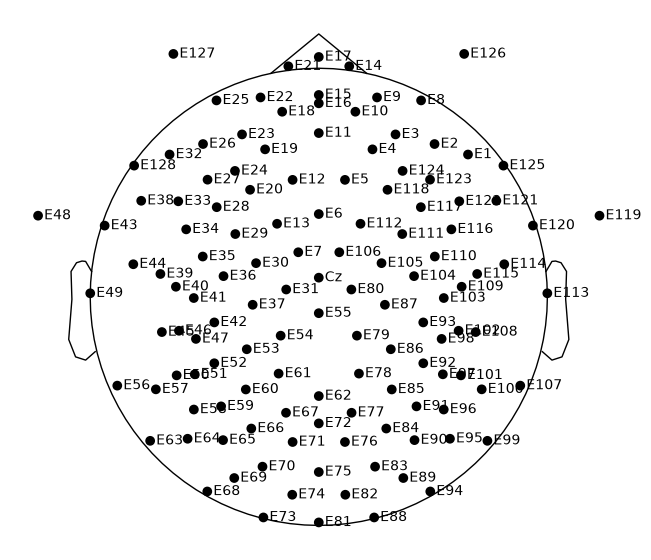

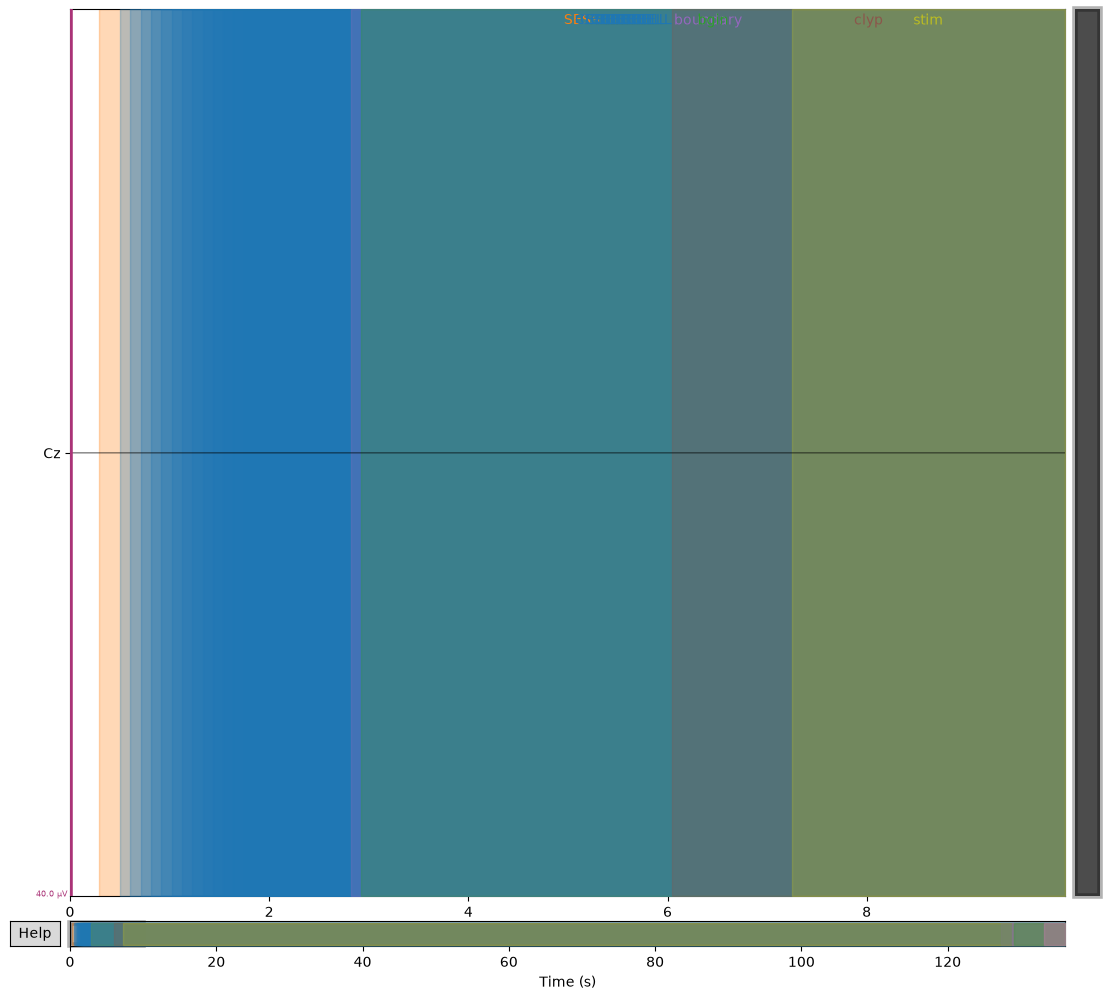

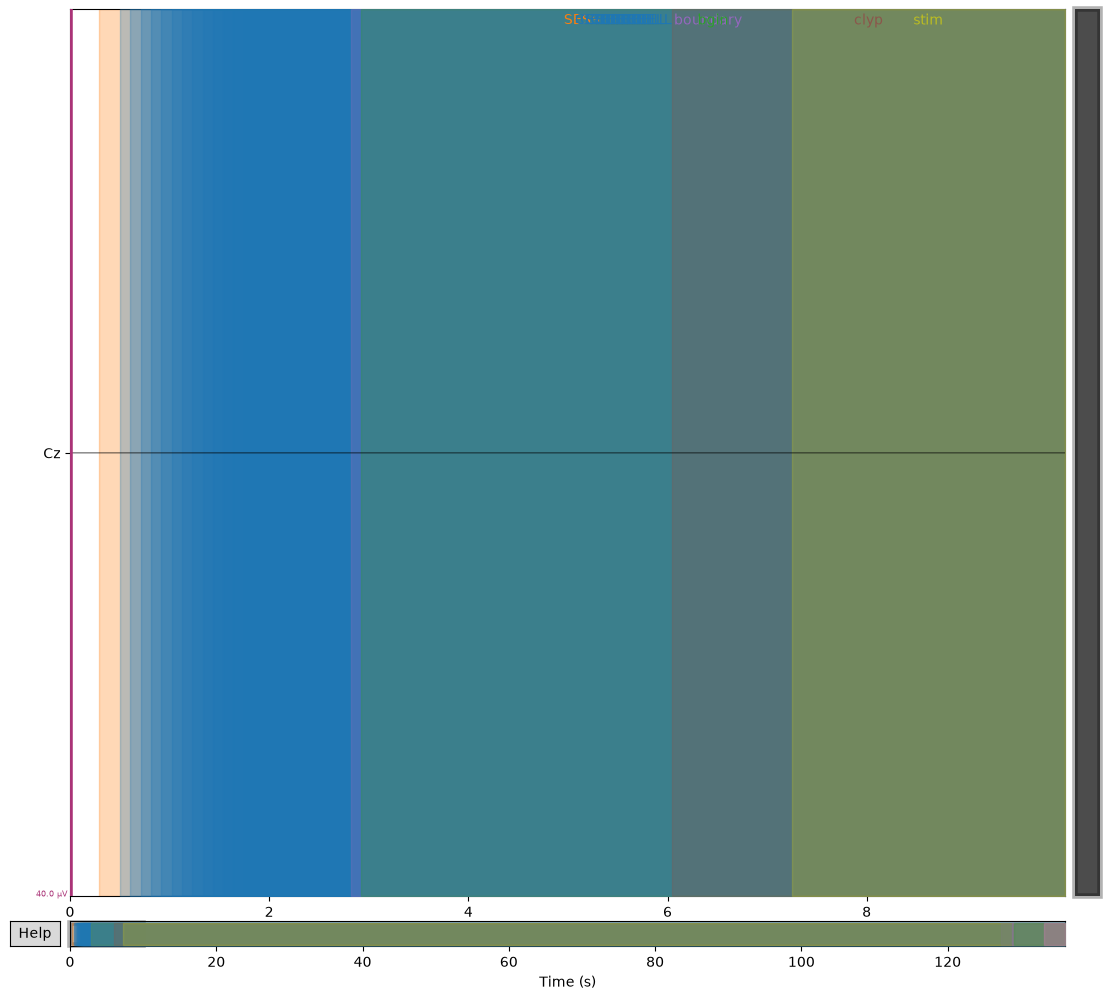

In [27]:
montage = mne.channels.make_standard_montage('GSN-HydroCel-129')
montage.plot()
a = df["raw"][0].copy()
a.ch_names
a.set_montage(montage)
a.plot(picks="Cz")

